# Modul 6 - Filter Spasial Low Pass Filter, High Pass Filter, Point Detection, Line Detection, Edge Detection

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [28]:
def convolution2d(image, kernel, stride=1, padding=1, show=True):
    # Balik kernel (konvolusi sejati)
    kernel = np.flipud(np.fliplr(kernel))
    k_h, k_w = kernel.shape
    img_h, img_w = image.shape

    # Tambah padding nol
    padded = np.pad(image.astype(np.float64),
                    ((padding, padding), (padding, padding)),
                    mode='constant', constant_values=0)

    # Ukuran output
    out_h = (img_h + 2 * padding - k_h) // stride + 1
    out_w = (img_w + 2 * padding - k_w) // stride + 1
    output = np.zeros((out_h, out_w))

    # Geser kernel di atas citra
    for i in range(out_h):
        for j in range(out_w):
            y, x = i * stride, j * stride
            output[i, j] = np.sum(padded[y:y + k_h, x:x + k_w] * kernel)

    # Clip ke 0-255 supaya valid sebagai citra
    output = np.clip(output, 0, 255).astype(np.uint8)

    # Tampilkan sebelum dan sesudah
    if show:
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(image, cmap='gray')
        plt.title('Asli')
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.imshow(output, cmap='gray')
        plt.title('Hasil Konvolusi')
        plt.axis('off')
        plt.show()

    return output

In [29]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

In [30]:
# Image Sharpen
kernel_sharpen = np.array([[0,-1,0],
                           [-1,5,-1],
                           [0,-1,0]])

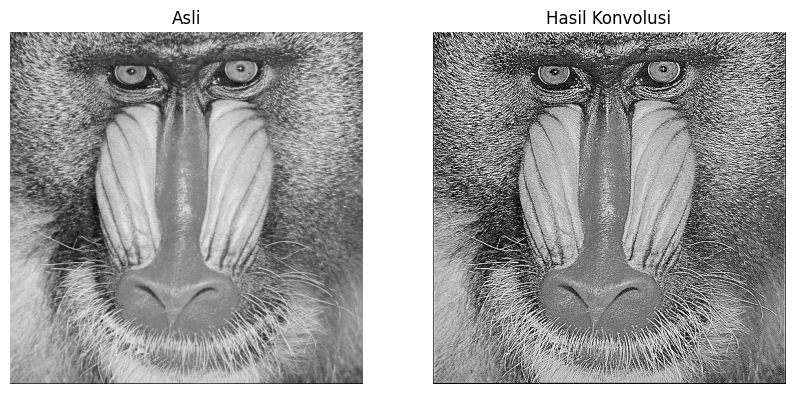

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0, 255,   0, ..., 255, 255,   0],
       [  0, 255, 179, ..., 249, 218,   0],
       ...,
       [  0, 255, 255, ..., 159, 183,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8)

In [31]:
convolution2d(img_gray,kernel_sharpen,1,2)

In [32]:
# Image Emboss
kernel_emboss = np.array([[-2,-1,0],
                           [-1,1,1],
                           [0,1,2]])

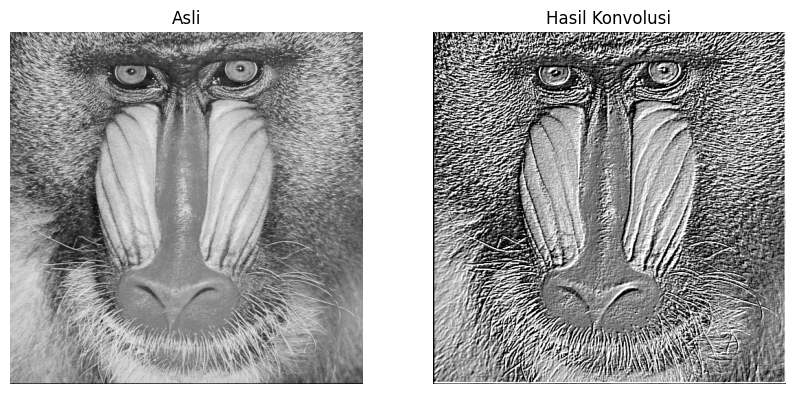

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0, 205, 177],
       [  0,   0, 255, ..., 255, 255, 255],
       ...,
       [  0, 123, 255, ..., 255, 255, 225],
       [  0, 156, 255, ..., 245, 237, 142],
       [  0,  11,  33, ...,  18,  12,   8]], dtype=uint8)

In [33]:
convolution2d(img_gray,kernel_emboss,1,2)

In [34]:
# Image Left Sobel Edge Detection
kernel_left_sobel = np.array([[1,0,-1],
                           [2,0,-2],
                           [1,0,-1]])

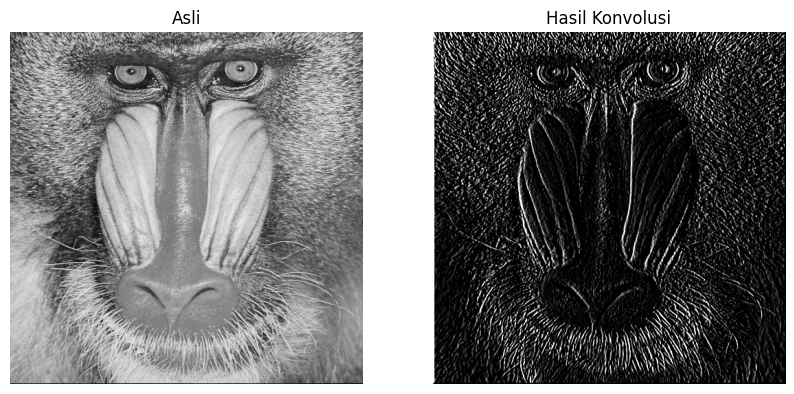

array([[145,  56,   0, ...,  64,   0,   0],
       [255, 213,   0, ..., 123,   0,   0],
       [255, 255,   0, ...,  35,   0,   0],
       ...,
       [255, 255,   0, ...,   0,   0,   0],
       [178, 163,   0, ...,   0,   0,   0],
       [ 11,  11,   2, ...,   0,   0,   0]], dtype=uint8)

In [35]:
convolution2d(img_gray,kernel_left_sobel,1,2)

In [36]:
# Image Canny Edge Detection
kernel_canny = np.array([[-1,-1,-1],
                         [-1,8,-1],
                         [-1,-1,-1]])

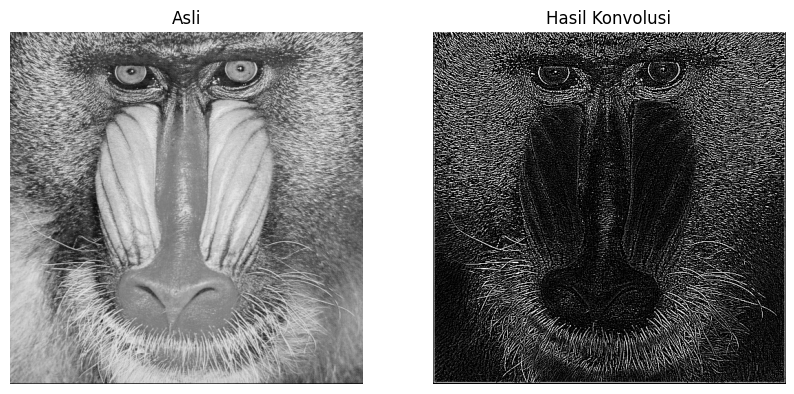

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0, 255,   0, ..., 255, 255,   0],
       [  0, 255, 165, ..., 225, 255,   0],
       ...,
       [  0, 255, 255, ..., 227, 255,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8)

In [37]:
convolution2d(img_gray,kernel_canny,1,2)

In [38]:
# Image Gaussian Blur
kernel_size = 21
sigma=math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @gaussian_kernel.transpose()

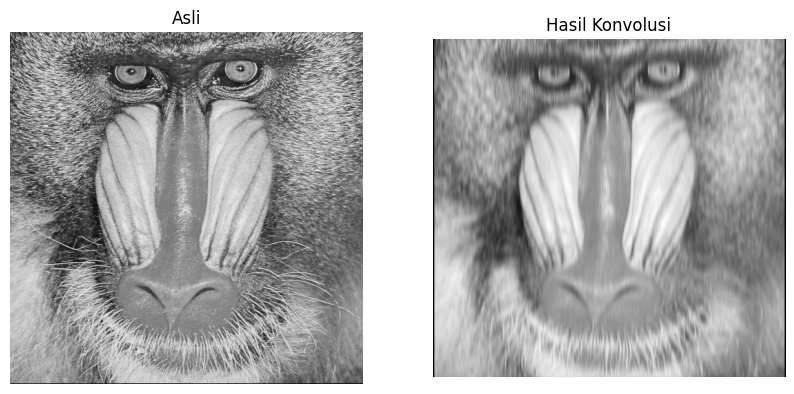

array([[  0,   0,  52, ..., 114,   0,   0],
       [  0,   0,  51, ..., 115,   0,   0],
       [  0,   0,  50, ..., 116,   0,   0],
       ...,
       [  0,   0, 137, ...,  79,   0,   0],
       [  0,   0, 133, ...,  78,   0,   0],
       [  0,   0, 127, ...,  76,   0,   0]], dtype=uint8)

In [ ]:
convolution2d(img_gray,gaussian_kernel,1,2)